# LokerLens — Evaluasi Ulang Model & Analisis Kesalahan (Sprint 3)

Tujuan: (1) mengevaluasi ulang model dengan **accuracy, precision, recall, F1-score**, dan (2) **menganalisis kesalahan prediksi**.

**Catatan penting:** `model_lokerlens.joblib` dilatih ulang pada *seluruh* dataset (untuk produksi), jadi tidak boleh dites pada data yang sama. Notebook ini membuat ulang pembagian train/test yang **identik** dengan notebook training (seed dan kode sama), melatih model yang sama pada bagian train, lalu mengevaluasinya pada **data uji yang belum pernah dilihat**. Model produksi dites pada data eksternal (bagian 7).

Output: `ml/reports/metrik_evaluasi.csv` dan `ml/reports/analisis_kesalahan.csv`.

## 1. Setup

In [1]:
import json, sys, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, roc_curve, precision_recall_curve)

warnings.filterwarnings("ignore")
SEED = 42
AMBANG = 0.50            # ambang klasifikasi untuk evaluasi (BR-05 prioritas tinggi dibahas di bagian 4)

ML_DIR = next(p for p in [Path.cwd(), Path.cwd().parent, Path.cwd() / "ml"] if (p / "data" / "processed").exists())
PATH_DATASET = ML_DIR / "data" / "processed" / "dataset_lokerlens_bersih.csv"
PATH_MODEL = ML_DIR / "models" / "model_lokerlens.joblib"
PATH_META = ML_DIR / "models" / "model_lokerlens_meta.json"
PATH_EKSTERNAL = ML_DIR / "data" / "eval" / "uji_eksternal.csv"
DIR_REPORT = ML_DIR / "reports"; DIR_REPORT.mkdir(exist_ok=True)

sys.path.insert(0, str(ML_DIR / "src"))
from lokerlens_infer import preprocess, periksa, _bobot_fitur

MODEL_FINAL = json.loads(PATH_META.read_text(encoding="utf-8"))["model_final"]
print("ML_DIR:", ML_DIR, "| model final:", MODEL_FINAL)

ML_DIR: c:\Users\tanst\LokerLens\ml | model final: Logistic Regression


## 2. Bangun ulang split train/test (identik dengan notebook training)

In [2]:
df = pd.read_csv(PATH_DATASET)[["id", "label", "deskripsi"]].dropna(subset=["label", "deskripsi"])
df["teks_bersih"] = df["deskripsi"].map(preprocess)
df = df[df["teks_bersih"].str.split().str.len() >= 5].drop_duplicates("teks_bersih").reset_index(drop=True)
df["grup"] = pd.factorize(df["teks_bersih"].map(lambda s: " ".join(s.split()[:10])))[0]
df["n_char"] = df["deskripsi"].str.len()

X, y, grp = df["teks_bersih"], df["label"], df["grup"]
idx_tr, idx_te = next(StratifiedGroupKFold(5, shuffle=True, random_state=SEED).split(X, y, grp))

def buat_tfidf():
    return TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_df=0.9, max_features=20000, sublinear_tf=True)

MODEL = {
    "Naive Bayes": MultinomialNB(alpha=0.5),
    "Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced", random_state=SEED),
    "SVM (linear)": CalibratedClassifierCV(LinearSVC(class_weight="balanced", random_state=SEED), cv=3),
    "Random Forest": RandomForestClassifier(n_estimators=300, class_weight="balanced", n_jobs=-1, random_state=SEED),
}[MODEL_FINAL]

pipe = Pipeline([("tfidf", buat_tfidf()), ("clf", MODEL)]).fit(X.iloc[idx_tr], y.iloc[idx_tr])
te = df.iloc[idx_te].copy()
te["proba"] = pipe.predict_proba(X.iloc[idx_te])[:, 1]
te["pred"] = (te["proba"] >= AMBANG).astype(int)
y_te = te["label"].values
print(f"Train: {len(idx_tr)} | Test: {len(te)} (asli {int((y_te == 0).sum())}, palsu {int((y_te == 1).sum())})")

Train: 659 | Test: 165 (asli 100, palsu 65)


## 3. Evaluasi: accuracy, precision, recall, F1

,nilai
accuracy,0.9818
precision_palsu,0.9844
recall_palsu,0.9692
f1_palsu,0.9767
precision_asli,0.9802
recall_asli,0.9900
f1_asli,0.9851
f1_macro,0.9809
roc_auc,0.9986
pr_auc,0.9980


              precision    recall  f1-score   support

        asli     0.9802    0.9900    0.9851       100
       palsu     0.9844    0.9692    0.9767        65

    accuracy                         0.9818       165
   macro avg     0.9823    0.9796    0.9809       165
weighted avg     0.9818    0.9818    0.9818       165

CI 95% accuracy : [0.958 1.   ] | CI 95% F1 palsu: [0.947 1.   ]


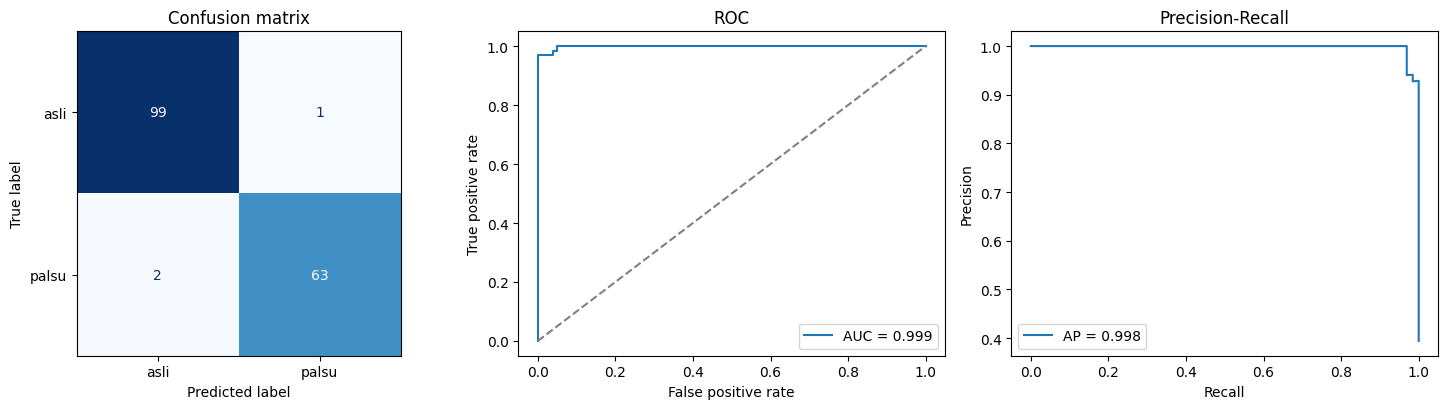

In [3]:
def hitung(y_true, y_pred, proba):
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision_palsu": precision_score(y_true, y_pred, zero_division=0),
        "recall_palsu": recall_score(y_true, y_pred, zero_division=0),
        "f1_palsu": f1_score(y_true, y_pred, zero_division=0),
        "precision_asli": precision_score(y_true, y_pred, pos_label=0, zero_division=0),
        "recall_asli": recall_score(y_true, y_pred, pos_label=0, zero_division=0),
        "f1_asli": f1_score(y_true, y_pred, pos_label=0, zero_division=0),
        "f1_macro": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "roc_auc": roc_auc_score(y_true, proba),
        "pr_auc": average_precision_score(y_true, proba),
    }

metrik = hitung(y_te, te["pred"].values, te["proba"].values)
tabel = pd.DataFrame(metrik, index=["nilai"]).T.round(4)
display(tabel)
print(classification_report(y_te, te["pred"], target_names=["asli", "palsu"], digits=4))

# interval kepercayaan 95% (bootstrap) karena data uji kecil
rng = np.random.default_rng(SEED); boot = []
for _ in range(1000):
    i = rng.integers(0, len(te), len(te))
    if len(set(y_te[i])) < 2: continue
    boot.append((accuracy_score(y_te[i], te["pred"].values[i]), f1_score(y_te[i], te["pred"].values[i])))
boot = np.array(boot)
ci = {"accuracy": np.percentile(boot[:, 0], [2.5, 97.5]), "f1_palsu": np.percentile(boot[:, 1], [2.5, 97.5])}
print("CI 95% accuracy :", ci["accuracy"].round(3), "| CI 95% F1 palsu:", ci["f1_palsu"].round(3))

fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
ConfusionMatrixDisplay(confusion_matrix(y_te, te["pred"]), display_labels=["asli", "palsu"]).plot(ax=ax[0], cmap="Blues", colorbar=False)
ax[0].set_title("Confusion matrix")
fpr, tpr, _ = roc_curve(y_te, te["proba"]); ax[1].plot(fpr, tpr, label=f"AUC = {metrik['roc_auc']:.3f}"); ax[1].plot([0, 1], [0, 1], "--", c="gray")
ax[1].set(xlabel="False positive rate", ylabel="True positive rate", title="ROC"); ax[1].legend()
pr, rc, _ = precision_recall_curve(y_te, te["proba"]); ax[2].plot(rc, pr, label=f"AP = {metrik['pr_auc']:.3f}")
ax[2].set(xlabel="Recall", ylabel="Precision", title="Precision-Recall"); ax[2].legend()
plt.tight_layout(); plt.show()

tabel.rename(columns={"nilai": "nilai"}).to_csv(DIR_REPORT / "metrik_evaluasi.csv")

**Cara membaca:** *precision palsu* = dari yang ditandai palsu, berapa yang benar-benar palsu. *Recall palsu* = dari semua lowongan palsu, berapa yang tertangkap (paling penting: palsu yang lolos berbahaya). Di sistem ini precision rendah berarti beban Analis naik, recall rendah berarti penipuan lolos.

## 4. Sensitivitas ambang (dasar penentuan BR-05)

In [4]:
rows = []
for th in [0.3, 0.5, 0.6, 0.7, 0.8, 0.9]:
    p = (te["proba"] >= th).astype(int)
    rows.append({"ambang": th, "ditandai": int(p.sum()), "precision_palsu": round(precision_score(y_te, p, zero_division=0), 3),
                 "recall_palsu": round(recall_score(y_te, p, zero_division=0), 3), "f1_palsu": round(f1_score(y_te, p, zero_division=0), 3),
                 "FP": int(((p == 1) & (y_te == 0)).sum()), "FN": int(((p == 0) & (y_te == 1)).sum())})
pd.DataFrame(rows)

,ambang,ditandai,precision_palsu,recall_palsu,f1_palsu,FP,FN
0,0.3,82,0.793,1.000,0.884,17,0
1,0.5,64,0.984,0.969,0.977,1,2
2,0.6,60,1.000,0.923,0.960,0,5
3,0.7,53,1.000,0.815,0.898,0,12
4,0.8,27,1.000,0.415,0.587,0,38
5,0.9,4,1.000,0.062,0.116,0,61


Basis database memakai skor **70** untuk status *Perlu Tinjauan*; `periksa()` memakai **0,80** untuk prioritas tinggi. Pilih satu nilai berdasarkan tabel ini (trade-off FP vs FN) dan tulis alasannya di laporan.

## 5. Analisis kesalahan

In [5]:
te["tipe"] = np.select([(te.label == 0) & (te.pred == 1), (te.label == 1) & (te.pred == 0)],
                       ["FP (asli ditandai palsu)", "FN (palsu lolos)"], default="benar")
err = te[te["tipe"] != "benar"].copy()
print("Jumlah salah:", len(err), "dari", len(te), "|", err["tipe"].value_counts().to_dict())

# kata yang mendorong ke PALSU (untuk FP) dan ke ASLI (untuk FN)
vec, clf = pipe.named_steps["tfidf"], pipe.named_steps["clf"]
w, fn = _bobot_fitur(clf), vec.get_feature_names_out()
def kata_dorong(teks, arah, n=5):
    x = vec.transform([teks]).multiply(w * arah).tocoo()
    pasang = sorted(zip(x.col, x.data), key=lambda p: -p[1])
    return ", ".join(fn[i] for i, v in pasang[:n] if v > 0)

err["kata_penyebab"] = [kata_dorong(t, 1 if tp.startswith("FP") else -1) for t, tp in zip(err["teks_bersih"], err["tipe"])]
err["ringkas"] = err["deskripsi"].str.replace(r"\s+", " ", regex=True).str[:160]
err = err.sort_values("proba", ascending=False)
pd.set_option("display.max_colwidth", 170)
display(err[["id", "tipe", "proba", "n_char", "kata_penyebab", "ringkas"]].round(3))

Jumlah salah: 3 dari 165 | {'FN (palsu lolos)': 2, 'FP (asli ditandai palsu)': 1}


,id,tipe,proba,n_char,kata_penyebab,ringkas
526,LK-0529,FP (asli ditandai palsu),0.510,226,"staff, ada, bpjs, helper, pria wanita",Helper Kualifikasi Pria/Wanita 17-27 Tahun tidak ada pengalaman (experience ) dan tidak bisa berbahasa inggris tidak apa asalkan mau belajar dan serius mau beke
59,LK-0060,FN (palsu lolos),0.397,283,"mampu, bekerja, tim, membuat, bersedia",BNN LOWONGAN KERJA Badan Narkotika Nasional (BNN) Posisi: Staf Bagian Umum BNNP Kualifikasi Umum: Usia maksimal 35 tahun Pendidikan minimal D3 semua jurusan Mam
215,LK-0217,FN (palsu lolos),0.389,591,"tiktok, tim, pengalaman, bergabung tim, mencari",Hallo! Saya adalah agen TikTok; dan saat ini kami sedang mencari mitra untuk bergabung dengan tim kami. Berdasarkan data konten dan komentar Anda; kami yakin An


### 5.1 Pola kesalahan

In [6]:
# (a) per panjang teks
te["panjang"] = pd.qcut(te["n_char"], 4, duplicates="drop")
by_len = te.groupby("panjang", observed=True).apply(lambda d: pd.Series({"n": len(d), "salah": int((d.tipe != "benar").sum()),
                                                      "error_rate_%": round(100 * (d.tipe != "benar").mean(), 1)}))
display(by_len)

# (b) kesalahan tipis (dekat batas) vs yakin
err["kategori_keyakinan"] = np.where((err.proba > 0.35) & (err.proba < 0.65), "dekat batas (0,35-0,65)", "salah dengan yakin")
display(err["kategori_keyakinan"].value_counts().to_frame("jumlah"))

# (c) rata-rata panjang: salah vs benar, per kelas
display(te.groupby(["label", te.tipe == "benar"])["n_char"].mean().round(0).unstack().rename(columns={True: "benar", False: "salah"}).rename(index={0: "asli", 1: "palsu"}))

,n,salah,error_rate_%
panjang,,,
"(36.999, 329.0]",42.0,2.0,4.8
"(329.0, 568.0]",41.0,0.0,0.0
"(568.0, 1014.0]",41.0,1.0,2.4
"(1014.0, 3250.0]",41.0,0.0,0.0


,jumlah
kategori_keyakinan,
"dekat batas (0,35-0,65)",3


tipe,salah,benar
label,,
asli,226.0,909.0
palsu,437.0,395.0


### 5.2 Kategorikan penyebab secara manual
Buka `ml/reports/analisis_kesalahan.csv` di Excel, baca tiap baris, lalu isi kolom **`penyebab_manual`** dengan salah satu kategori, misalnya:

- **Gaya penulisan sumber** (palsu berformat rapi seperti iklan resmi, atau asli bergaya santai)
- **Teks terlalu pendek/informasi kurang**
- **Label diragukan / salah label**
- **Kata pemicu umum** (mis. "gaji", "daftar", "link" muncul di iklan asli)
- **Pola penipuan yang tidak ada di data latih**

Hitung kategori terbanyak, lalu jadikan dasar analisis dan rekomendasi di laporan.

In [7]:
out = err[["id", "tipe", "proba", "n_char", "kata_penyebab", "deskripsi"]].copy()
out["penyebab_manual"] = ""
out.round(4).to_csv(DIR_REPORT / "analisis_kesalahan.csv", index=False, encoding="utf-8-sig")
print("Tersimpan:", DIR_REPORT / "analisis_kesalahan.csv", f"({len(out)} baris)")

Tersimpan: c:\Users\tanst\LokerLens\ml\reports\analisis_kesalahan.csv (3 baris)


## 6. Kata paling berpengaruh pada model
Cek manual: kata yang masuk akal sebagai ciri penipuan, atau hanya gaya penulisan sumber?

In [8]:
urut = np.argsort(w)
print("-> PALSU:", [fn[i] for i in urut[::-1][:20]])
print("-> ASLI :", [fn[i] for i in urut[:20]])

-> PALSU: ['pendaftaran', 'pt', 'indonesia', 'dibuka', 'lowongan', 'rekrutmen', 'lowongan kerja', 'link', 'resmi', 'nominalrp', 'loker', 'daftar', 'staff', 'bumn', 'gaji', 'info', 'bersama', 'open', 'bio', 'terbaru']
-> ASLI : ['memiliki', 'melakukan', 'jawab', 'pengalaman', 'tim', 'bertanggung jawab', 'bertanggung', 'bidang', 'memiliki pengalaman', 'penjualan', 'produk', 'mampu', 'target', 'minimal', 'mencari', 'memastikan', 'kandidat', 'operasional', 'sales', 'pelanggan']


## 7. Uji pada data eksternal (belum pernah dilihat model)
Ini uji paling jujur untuk **generalisasi**. Isi `ml/data/eval/uji_eksternal.csv` (kolom: `deskripsi,label,sumber`; 0 = asli, 1 = palsu) dengan lowongan dari **sumber lain** (portal berbeda, atau penipuan yang ditulis rapi). Makin banyak makin baik (minimal 30 per kelas). Kalau file belum ada, notebook membuat template berisi contoh awal.

In [9]:
if not PATH_EKSTERNAL.exists():
    PATH_EKSTERNAL.parent.mkdir(parents=True, exist_ok=True)
    contoh = [
        ("PT Karya Mandiri membuka lowongan Staff Administrasi. Gaji Rp9.000.000 per bulan tanpa pengalaman. Lolos seleksi wajib membayar biaya administrasi Rp250.000 via transfer sebelum wawancara. Hubungi WhatsApp 081234567890.", 1, "contoh_manual"),
        ("Dibuka lowongan Operator Produksi, lulusan SMA/SMK, penghasilan Rp8 juta/bulan, tanpa tes. Bayar biaya seragam dan pelatihan Rp300.000 untuk konfirmasi. Kirim data ke email hrd.karya@gmail.com.", 1, "contoh_manual"),
        ("Kami mencari Customer Service untuk bergabung di perusahaan terpercaya. Fasilitas lengkap, jenjang karir jelas. Wawancara dilakukan di hotel. Transfer deposit Rp200.000 sebagai tanda keseriusan.", 1, "contoh_manual"),
        ("Rekrutmen resmi Tenaga Admin Gudang. Gaji Rp10.000.000, fresh graduate diterima. Wajib transfer biaya pendaftaran dan tes kesehatan ke rekening panitia sebelum jadwal wawancara.", 1, "contoh_manual"),
        ("Lowongan Kasir toko. Gaji tinggi tanpa syarat pengalaman. Daftar lewat WhatsApp dan bayar uang registrasi Rp150.000.", 1, "contoh_manual"),
        ("Dicari Barista, shift pagi, minimal SMA, sabar dan ramah ya. Gaji sesuai UMK, ada uang makan. Bawa CV langsung ke kafe kami, tanya Kak Dina.", 0, "contoh_manual"),
        ("Butuh driver antar barang, punya SIM A, paham jalan kota Surabaya. Gaji harian plus bonus, mulai kerja minggu depan. Chat aja untuk info, gratis tanpa biaya apa pun.", 0, "contoh_manual"),
        ("Toko bangunan kami membuka lowongan Staf Gudang. Kerja 6 hari, jam 08.00-16.00, BPJS Ketenagakerjaan. Kirim lamaran ke email resmi perusahaan atau datang ke toko.", 0, "contoh_manual"),
        ("Dibutuhkan Akuntan Junior, S1 Akuntansi, pengalaman 1 tahun, menguasai Excel dan software akuntansi. Wawancara di kantor kami. Kirim CV ke hrd@perusahaan.co.id.", 0, "contoh_manual"),
        ("Klinik gigi kami mencari Asisten Dokter Gigi, lulusan D3 Keperawatan Gigi, ramah dan teliti. Lamaran ke email klinik, tidak dipungut biaya apa pun.", 0, "contoh_manual"),
    ]
    pd.DataFrame(contoh, columns=["deskripsi", "label", "sumber"]).to_csv(PATH_EKSTERNAL, index=False, encoding="utf-8-sig")
    print("Template dibuat:", PATH_EKSTERNAL, "-> TAMBAH data dari sumber lain, lalu jalankan ulang sel ini.")

ext = pd.read_csv(PATH_EKSTERNAL).dropna(subset=["deskripsi", "label"])
model_prod = joblib.load(PATH_MODEL)
ext["proba"] = [periksa(model_prod, deskripsi=d)["confidence_score"] / 100 for d in ext["deskripsi"]]
ext["pred"] = (ext["proba"] >= AMBANG).astype(int)
print(f"n = {len(ext)} (asli {int((ext.label == 0).sum())}, palsu {int((ext.label == 1).sum())})")
if len(ext) < 60:
    print("[!] Data eksternal masih sedikit, jadi angka di bawah hanya gambaran kasar. Tambah minimal 30 per kelas.")
if ext["label"].nunique() == 2:
    display(pd.DataFrame(hitung(ext["label"].values, ext["pred"].values, ext["proba"].values), index=["eksternal"]).T.round(4))
display(ext.assign(ringkas=ext["deskripsi"].str[:90])[["label", "pred", "proba", "ringkas"]].round(3))

Template dibuat: c:\Users\tanst\LokerLens\ml\data\eval\uji_eksternal.csv -> TAMBAH data dari sumber lain, lalu jalankan ulang sel ini.
n = 10 (asli 5, palsu 5)
[!] Data eksternal masih sedikit, jadi angka di bawah hanya gambaran kasar. Tambah minimal 30 per kelas.


,eksternal
accuracy,0.5000
precision_palsu,0.5000
recall_palsu,1.0000
f1_palsu,0.6667
precision_asli,0.0000
recall_asli,0.0000
f1_asli,0.0000
f1_macro,0.3333
roc_auc,0.9600
pr_auc,0.9667


,label,pred,proba,ringkas
0,1,1,0.799,PT Karya Mandiri membuka lowongan Staff Administrasi. Gaji Rp9.000.000 per bulan tanpa pen
1,1,1,0.874,"Dibuka lowongan Operator Produksi, lulusan SMA/SMK, penghasilan Rp8 juta/bulan, tanpa tes."
2,1,1,0.603,"Kami mencari Customer Service untuk bergabung di perusahaan terpercaya. Fasilitas lengkap,"
3,1,1,0.809,"Rekrutmen resmi Tenaga Admin Gudang. Gaji Rp10.000.000, fresh graduate diterima. Wajib tra"
4,1,1,0.741,Lowongan Kasir toko. Gaji tinggi tanpa syarat pengalaman. Daftar lewat WhatsApp dan bayar
5,0,1,0.564,"Dicari Barista, shift pagi, minimal SMA, sabar dan ramah ya. Gaji sesuai UMK, ada uang mak"
6,0,1,0.590,"Butuh driver antar barang, punya SIM A, paham jalan kota Surabaya. Gaji harian plus bonus,"
7,0,1,0.656,"Toko bangunan kami membuka lowongan Staf Gudang. Kerja 6 hari, jam 08.00-16.00, BPJS Keten"
8,0,1,0.527,"Dibutuhkan Akuntan Junior, S1 Akuntansi, pengalaman 1 tahun, menguasai Excel dan software"
9,0,1,0.564,"Klinik gigi kami mencari Asisten Dokter Gigi, lulusan D3 Keperawatan Gigi, ramah dan telit"


## 8. Ringkasan siap salin ke laporan

In [10]:
m = metrik
print(f'''Evaluasi ulang model {MODEL_FINAL} pada data uji ({len(te)} lowongan: {int((y_te == 0).sum())} asli, {int((y_te == 1).sum())} palsu), ambang {AMBANG}:
- Accuracy        : {m["accuracy"]:.3f}  (CI 95%: {ci["accuracy"][0]:.3f}-{ci["accuracy"][1]:.3f})
- Precision palsu : {m["precision_palsu"]:.3f}
- Recall palsu    : {m["recall_palsu"]:.3f}
- F1-score palsu  : {m["f1_palsu"]:.3f}  (CI 95%: {ci["f1_palsu"][0]:.3f}-{ci["f1_palsu"][1]:.3f})
- ROC-AUC         : {m["roc_auc"]:.3f}
Kesalahan: {len(err)} dari {len(te)} ({(err.tipe.str.startswith("FP")).sum()} asli ditandai palsu, {(err.tipe.str.startswith("FN")).sum()} palsu lolos).''')

Evaluasi ulang model Logistic Regression pada data uji (165 lowongan: 100 asli, 65 palsu), ambang 0.5:
- Accuracy        : 0.982  (CI 95%: 0.958-1.000)
- Precision palsu : 0.984
- Recall palsu    : 0.969
- F1-score palsu  : 0.977  (CI 95%: 0.947-1.000)
- ROC-AUC         : 0.999
Kesalahan: 3 dari 165 (1 asli ditandai palsu, 2 palsu lolos).


### Kerangka analisis untuk laporan
1. **Hasil metrik** (tabel di bagian 3) dan perbandingan dengan hasil CV di notebook training.
2. **Kesalahan:** jumlah FP dan FN, dan mana yang lebih berbahaya (FN = penipuan lolos).
3. **Pola penyebab** (bagian 5.1 dan kategori manual di CSV).
4. **Generalisasi:** hasil data eksternal (bagian 7) dibanding data uji internal. Kalau turun jauh, model belajar gaya sumber, bukan penipuan.
5. **Keterbatasan:** asli dari KarirHub, palsu dari TurnBackHoax; data kecil.
6. **Rekomendasi:** tambah data dari sumber lain dan penipuan berformat rapi, tinjau ulang label, tentukan ambang BR-05, pertahankan keputusan akhir di Analis.